# Manipulating pipeline tables - Brazillian mining public data 

Read the stored parquet files with pandas, run queries with duckdb (in order to benefit from the practicity of using SQL), visualize data using matplotlib

> Required: run at least one pipeline in order to store the data in parquet files on MiniIo's S3 bucket successfuly.


## 1. Connection

- The goal here is connecting with the S3 bucket, and show which files are available

In [94]:
import decimal, os
import matplotlib.pyplot as plt
import pandas as pd
import s3fs


S3 = {"client_kwargs": 
          {"endpoint_url": os.environ.get("S3_ENDPOINT", "http://minio:9000")}, # creds are stored in environment variables
      "use_listings_cache": False}

BASE = "lake/estudo"

fs = s3fs.S3FileSystem(**S3)

# grabs everything under "lake/"
files = pd.DataFrame(fs.find(BASE, detail=True).values())
# creates column with file names under estudo folder
files["tabela"] = files["name"].str.removeprefix(BASE + "/").str.split("/").str[0]

inv = (
    files[~files["tabela"].str.startswith("_")] # filter out control folder
    .assign(is_parquet=lambda x: x["name"].str.endswith(".parquet")) # list only parquet files
    .groupby("tabela", as_index=False)
    .agg(arquivos=("is_parquet", "sum"),
        Mib=("size", lambda s: round(s.sum() /2**20, 1))
        )
)

inv

,tabela,arquivos,Mib
0,analises,2,0.0
1,anm_amb_producao,1,0.2
2,anm_cfem_arrecadacao,2,1.0
3,anm_dipem_investimento,1,0.7
4,anm_scm_evento,4,100.7
5,anm_scm_municipio,2,3.0
6,anm_scm_pessoa,3,13.7
7,anm_scm_processo,3,6.5
8,anm_scm_substancia,2,6.8
9,anm_scm_titulo,3,6.2


## 2. Pandas + DuckDB

- Here you will build the query and change the source table by index so it's quicker than writing it by name

In [95]:
import duckdb

df = pd.read_parquet(f"{BASE}/{str(inv['tabela'][2])}", filesystem = fs)
df["valor_recolhido"] = df["valor_recolhido"].astype("float64")

query = duckdb.sql("""
        SELECT 
        YEAR(ano_mes) AS 'Ano',
        MONTH(ano_mes) AS 'Mês',
        uf AS UF,
        substancia,
        FLOOR(SUM(valor_recolhido)) AS 'valor recolhido'
        FROM df 
        GROUP BY ano_mes, uf, substancia
    """).df()

query


,Ano,Mês,UF,substancia,valor recolhido
0,2015,1,GO,OURO,635295.0
1,2015,1,GO,FERRO,5984.0
2,2015,1,PA,OURO,221317.0
3,2015,1,SP,FOSFATO,301534.0
4,2015,1,SP,BAUXITA,67801.0
...,...,...,...,...,...
4194,2026,4,SP,FERRO,11074.0
4195,2026,5,MA,OURO,1242470.0
4196,2026,5,MA,FERRO,32.0
4197,2026,6,MA,OURO,1092804.0


## 3. Dataviz via matplotlib

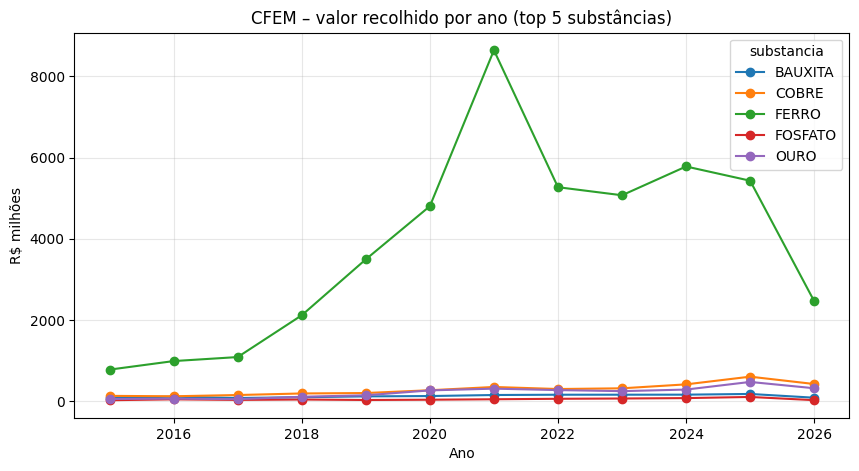

In [99]:
# CFEM: 5 ores with most collection
top = query.groupby("substancia")["valor recolhido"].sum().nlargest(5).index

pivot = (
    query[query["substancia"].isin(top)]
    .pivot_table(index="Ano", columns="substancia", values="valor recolhido", aggfunc="sum")
    / 1e6
)
pivot
ax = pivot.plot(figsize=(10, 5), marker="o")
ax.set_title("CFEM – valor recolhido por ano (top 5 substâncias)")
ax.set_xlabel("Ano")
ax.set_ylabel("R$ milhões")
ax.grid(alpha=0.3)
plt.show()


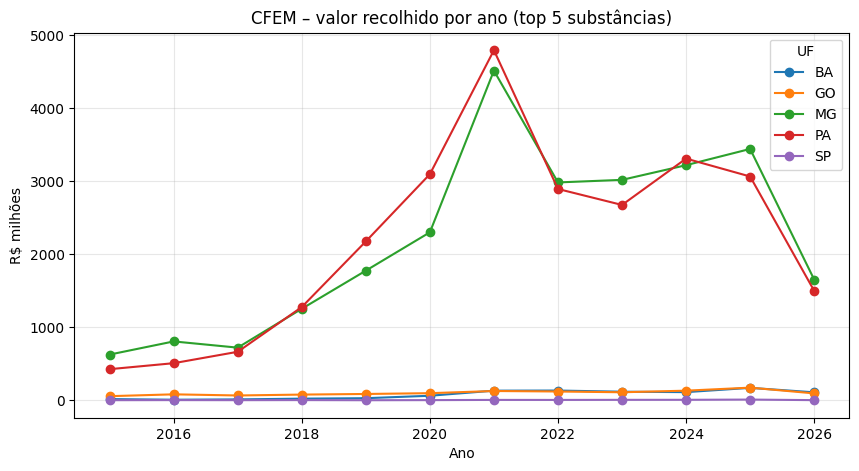

In [100]:
# Quickly narrowing to the most collected one, which is iron

iron = query[query["substancia"] == "FERRO"]

top = iron.groupby("UF")["valor recolhido"].sum().nlargest(5).index

pivot = (
    query[query["UF"].isin(top)]
    .pivot_table(index="Ano", columns="UF", values="valor recolhido", aggfunc="sum")
    / 1e6
)

ax = pivot.plot(figsize=(10, 5), marker="o")
ax.set_title("CFEM – valor recolhido por ano (top 5 substâncias)")
ax.set_xlabel("Ano")
ax.set_ylabel("R$ milhões")
ax.grid(alpha=0.3)
plt.show()

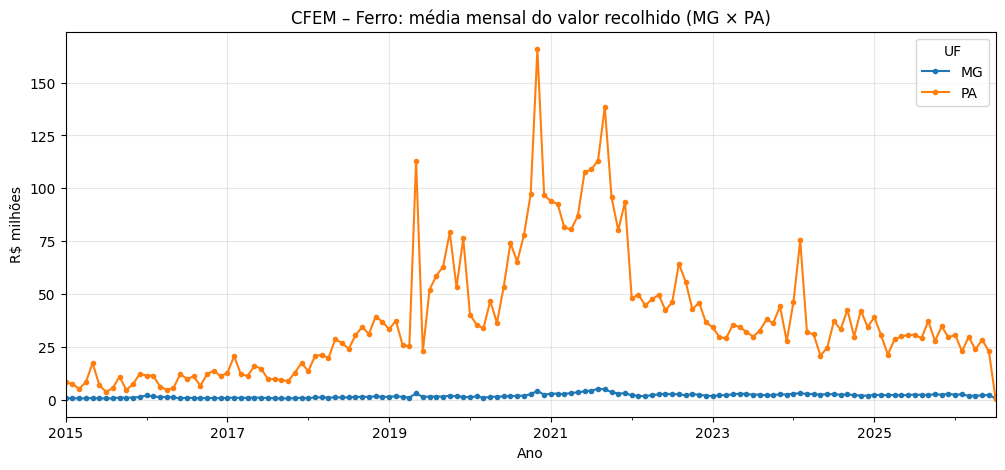

In [101]:
# Narrowing even further to the two states with most collections

query2 = duckdb.sql("""
    SELECT
        ano_mes,
        UPPER(TRIM(uf)) AS UF,
        AVG(valor_recolhido) AS media
    FROM df
    WHERE 
    1 = 1
      AND UPPER(TRIM(substancia)) = 'FERRO'
      AND UPPER(TRIM(uf)) IN ('MG', 'PA')
    GROUP BY ano_mes, UPPER(TRIM(uf))
    ORDER BY ano_mes
""").df()

pivot = query2.pivot(index="ano_mes", columns="UF", values="media") / 1e6

ax = pivot.plot(figsize=(12, 5), marker="o", markersize=3)
ax.set_title("CFEM – Ferro: média mensal do valor recolhido (MG × PA)")
ax.set_xlabel("Ano")
ax.set_ylabel("R$ milhões")
ax.grid(alpha=0.3)
plt.show()

## 4. Quick analytics

- Simple questions answered with SQL on the `query` table, then plotted

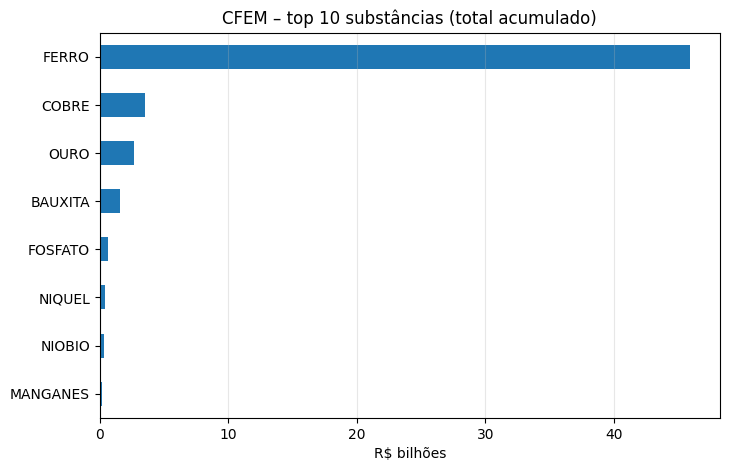

In [102]:
# Which ores collect the most? (all years)

by_ore = duckdb.sql("""
    SELECT substancia, SUM("valor recolhido") / 1e9 AS bilhoes
    FROM query
    GROUP BY substancia
    ORDER BY bilhoes DESC
    LIMIT 10
""").df().sort_values("bilhoes")  # sorted ascending so the biggest bar ends up on top

ax = by_ore.plot.barh(x="substancia", y="bilhoes", legend=False, figsize=(8, 5))
ax.set_title("CFEM – top 10 substâncias (total acumulado)")
ax.set_xlabel("R$ bilhões")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.3)
plt.show()

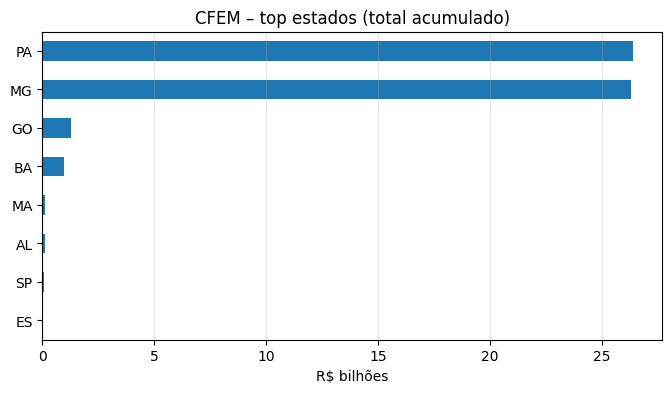

In [103]:
# Which states collect the most? (all years)

by_uf = duckdb.sql("""
    SELECT UF, SUM("valor recolhido") / 1e9 AS bilhoes
    FROM query
    GROUP BY UF
    ORDER BY bilhoes DESC
    LIMIT 10
""").df().sort_values("bilhoes")

ax = by_uf.plot.barh(x="UF", y="bilhoes", legend=False, figsize=(8, 4))
ax.set_title("CFEM – top estados (total acumulado)")
ax.set_xlabel("R$ bilhões")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.3)
plt.show()

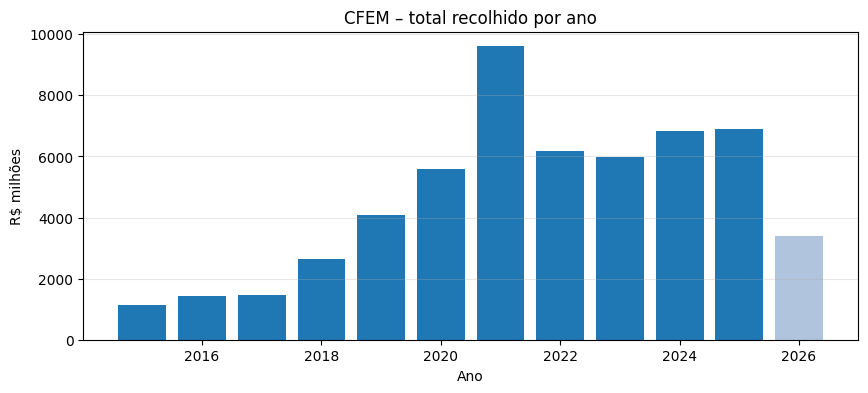

In [104]:
# Total collected per year (2026 is incomplete, so it is shown in a lighter color)

year = duckdb.sql("""
    SELECT Ano, SUM("valor recolhido") / 1e6 AS milhoes
    FROM query
    GROUP BY Ano
    ORDER BY Ano
""").df()

colors = ["tab:blue" if a < 2026 else "lightsteelblue" for a in year["Ano"]]

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(year["Ano"], year["milhoes"], color=colors)
ax.set_title("CFEM – total recolhido por ano")
ax.set_xlabel("Ano")
ax.set_ylabel("R$ milhões")
ax.grid(axis="y", alpha=0.3)
plt.show()

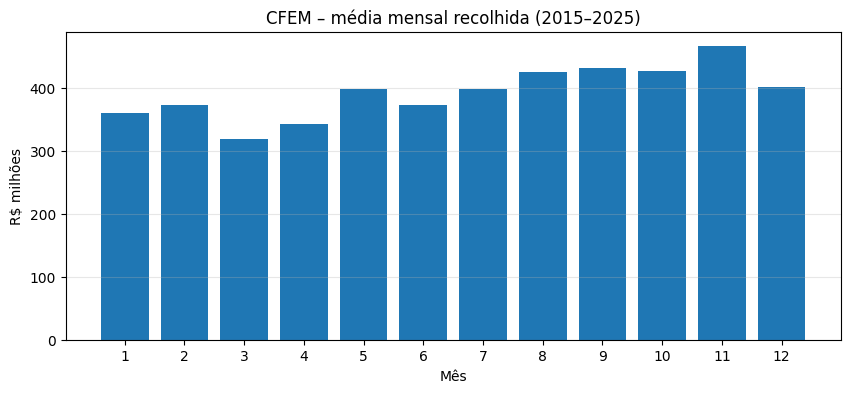

In [105]:
# Is there a seasonal pattern? Average collection per month (2026 left out, it is incomplete)

month = duckdb.sql("""
    SELECT "Mês", AVG(total) / 1e6 AS milhoes
    FROM (
        SELECT Ano, "Mês", SUM("valor recolhido") AS total
        FROM query
        WHERE Ano < 2026
        GROUP BY Ano, "Mês"
    )
    GROUP BY "Mês"
    ORDER BY "Mês"
""").df()

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(month["Mês"], month["milhoes"])
ax.set_xticks(range(1, 13))
ax.set_title("CFEM – média mensal recolhida (2015–2025)")
ax.set_xlabel("Mês")
ax.set_ylabel("R$ milhões")
ax.grid(axis="y", alpha=0.3)
plt.show()

## 5. Crossing tables

- DuckDB sees every DataFrame by its variable name, so a `JOIN` between tables is just SQL
- Keys in common: `substancia`, `ano` and `uf`

In [111]:
# Loading two more tables: DIPEM (declared investment) and SIGBM (dams)

dipem = pd.read_parquet(f"{BASE}/anm_dipem_investimento", filesystem=fs)
dipem["valor_rs"] = dipem["valor_rs"].astype("float64")

barragem = pd.read_parquet(f"{BASE}/anm_sigbm_barragem", filesystem=fs,
                           columns=["id_barragem", "uf", "categoria_risco"])

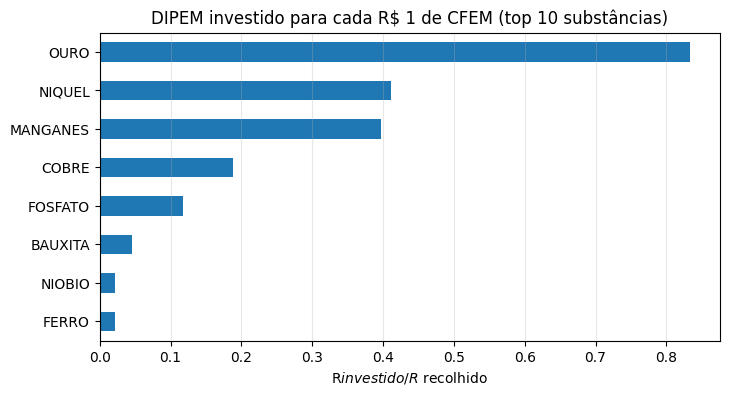

In [108]:
# CFEM x DIPEM by ore: how much is invested for each R$ 1 collected?

ore = duckdb.sql("""
    WITH c AS (SELECT substancia, SUM(valor_recolhido) AS cfem FROM df GROUP BY substancia),
         d AS (SELECT substancia, SUM(valor_rs) AS invest FROM dipem GROUP BY substancia)
    SELECT substancia, invest / cfem AS razao
    FROM c
    JOIN d USING (substancia)
    ORDER BY cfem DESC
    LIMIT 10
""").df().sort_values("razao")

ax = ore.plot.barh(x="substancia", y="razao", legend=False, figsize=(8, 4))
ax.set_title("DIPEM investido para cada R$ 1 de CFEM (top 10 substâncias)")
ax.set_xlabel("R$ investido / R$ recolhido")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.3)
plt.show()

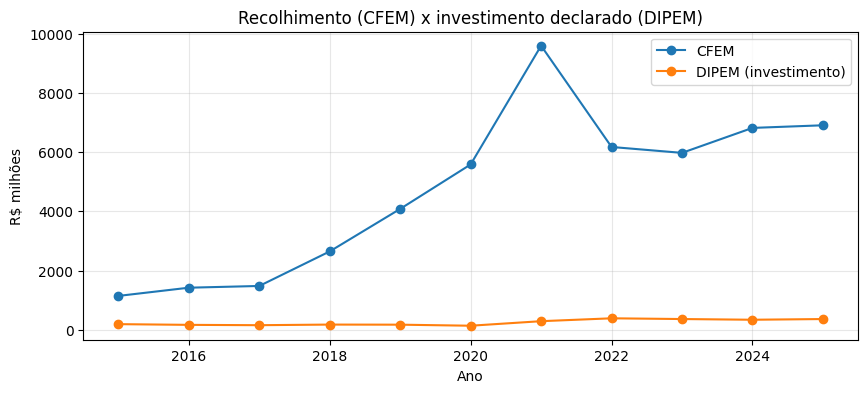

In [109]:
# CFEM x DIPEM by year (2015 onwards, when CFEM data starts)

years = duckdb.sql("""
    WITH c AS (SELECT YEAR(ano_mes) AS ano, SUM(valor_recolhido) AS cfem FROM df GROUP BY ano),
         d AS (SELECT ano, SUM(valor_rs) AS invest FROM dipem GROUP BY ano)
    SELECT ano, cfem / 1e6 AS "CFEM", invest / 1e6 AS "DIPEM (investimento)"
    FROM c
    JOIN d USING (ano)
    ORDER BY ano
""").df().set_index("ano")

ax = years.plot(figsize=(10, 4), marker="o")
ax.set_title("Recolhimento (CFEM) x investimento declarado (DIPEM)")
ax.set_xlabel("Ano")
ax.set_ylabel("R$ milhões")
ax.grid(alpha=0.3)
plt.show()

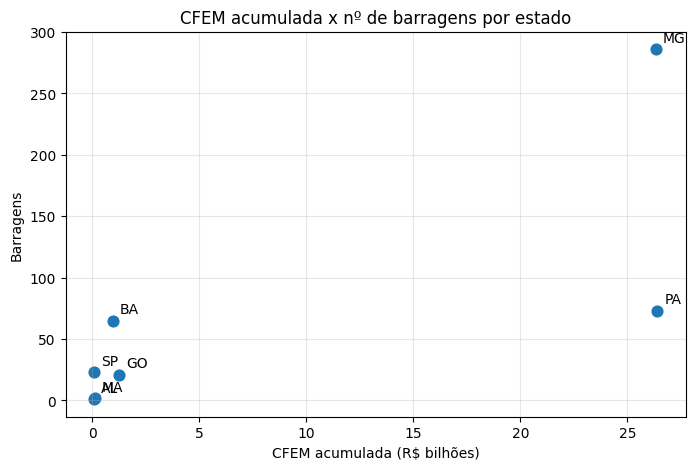

In [110]:
# CFEM x dams by state: do the states that collect more have more dams?

uf = duckdb.sql("""
    WITH c AS (SELECT UPPER(TRIM(uf)) AS uf, SUM(valor_recolhido) AS cfem FROM df GROUP BY 1),
         b AS (SELECT UPPER(TRIM(uf)) AS uf, COUNT(*) AS barragens,
                      COUNT(*) FILTER (WHERE categoria_risco = 'Alta') AS alto_risco
               FROM barragem GROUP BY 1)
    SELECT uf, cfem / 1e9 AS cfem_bi, barragens, alto_risco
    FROM c
    JOIN b USING (uf)
""").df()

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(uf["cfem_bi"], uf["barragens"], s=60)
for _, r in uf.iterrows():
    ax.annotate(r["uf"], (r["cfem_bi"], r["barragens"]), xytext=(5, 5), textcoords="offset points")
ax.set_title("CFEM acumulada x nº de barragens por estado")
ax.set_xlabel("CFEM acumulada (R$ bilhões)")
ax.set_ylabel("Barragens")
ax.grid(alpha=0.3)
plt.show()